In [1]:
# Copyright (C) 2026 Advanced Micro Devices, Inc. All rights reserved.
#
# SPDX-License-Identifier: BSD-3-Clause
#
# Portions of this file consist of AI-generated content. AI-assisted
# content has been reviewed and validated by the authors.

# A digital twin of the SO-101, from first principles

A digital twin is only useful if code cannot tell it from the robot. That
reduces to three claims, each checked below with a measurement:

1. **It moves like the arm** - same command interface, same servo dynamics.
2. **It sees like the arm** - a camera rendered where the real one is mounted.
3. **It feels like the arm** - gripper current that comes from contact.

With those in place, follow one command from words to a grasp: find the
named object with the wrist camera and reach it with inverse kinematics.

Then the payoff: the twin console of `./run_pipeline.sh --digital-twin`, with
voice control - you speak, and the workshop's own behaviors drive the twin.

What is simulated: the arm, its servos, the wrist camera and the table
scene (MuJoCo). What is real: everything above the arm transport - your
webcam and microphone, YOLOv26s pose and detection, MediaPipe Hands, the
mapper, Whisper, the Llama intent parser and the behaviors. Everything but
llama-server runs inside this kernel through section 4. In section 5 the
twin becomes a ROS 2 node, the way the full system runs it: this notebook
starts it on a ROS domain of its own and drives it with the arm client
`01_behavior.ipynb` uses for the real arm, so section 5 needs ROS 2.

## Compute placement

The pipeline is powered by AI models that utilize every subsystem of the APU. Each workload runs on the subsystem whose strengths best match its requirements.

<table style="border-collapse: collapse">
<thead>
<tr><th style="background-color: rgba(128, 128, 128, 0.2); border: 1px solid rgba(128, 128, 128, 0.4)">Task</th><th style="border: 1px solid rgba(128, 128, 128, 0.4)">Model or algorithm</th><th style="border: 1px solid rgba(128, 128, 128, 0.4)">What it does</th><th style="border: 1px solid rgba(128, 128, 128, 0.4)">Runs on</th><th style="border: 1px solid rgba(128, 128, 128, 0.4)">Runtime</th></tr>
</thead>
<tbody>
<tr style="background-color: rgba(0, 0, 0, 0)"><td rowspan="3" valign="top" style="background-color: rgba(128, 128, 128, 0.2); vertical-align: top; border: 1px solid rgba(128, 128, 128, 0.4)">Voice control</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">WebRTC VAD, a Gaussian mixture model</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">finds where a spoken sentence starts and ends</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">CPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)"><code>webrtcvad</code> (C library)</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td style="border: 1px solid rgba(128, 128, 128, 0.4)">Whisper-base</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">speech → text</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">CPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">ONNX Runtime</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td style="border: 1px solid rgba(128, 128, 128, 0.4)">Llama 3.2 3B Instruct (Q4_K_M)</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">text → command</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">iGPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)"><code>llama.cpp</code> <code>llama-server</code> (HIP)</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td rowspan="2" valign="top" style="background-color: rgba(128, 128, 128, 0.2); vertical-align: top; border: 1px solid rgba(128, 128, 128, 0.4)">Gestures</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">YOLOv26s-pose</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">finds your body and wrist</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">NPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">ONNX Runtime, VitisAI EP</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td style="border: 1px solid rgba(128, 128, 128, 0.4)">MediaPipe Hands</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">detects the hand gesture (pinch, roll)</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">CPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">MediaPipe Tasks</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td rowspan="2" valign="top" style="background-color: rgba(128, 128, 128, 0.2); vertical-align: top; border: 1px solid rgba(128, 128, 128, 0.4)">Object localization</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">YOLOv26s-detect</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">finds the named object in the arm camera</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">NPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">ONNX Runtime, VitisAI EP</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td style="border: 1px solid rgba(128, 128, 128, 0.4)">Localization and inverse kinematics</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">places the object on the table and solves the grasp</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">CPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">NumPy, MuJoCo</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td valign="top" style="background-color: rgba(128, 128, 128, 0.2); vertical-align: top; border: 1px solid rgba(128, 128, 128, 0.4)">Digital twin</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">MuJoCo 3D simulation</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">simulates the arm and the table scene</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">CPU (rendering on the iGPU)</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">MuJoCo, EGL</td></tr>
</tbody>
</table>

In [2]:
# workshop bootstrap: the detector, hand tracker, Llama parser and dispatcher
# come from the finished reference code in solution/ (no TODO stubs). The twin
# itself is shared code in so101_sim/ and common/. The config then swaps the
# Feetech bus for the MuJoCo twin, in this kernel.
import sys, pathlib, threading, time

# find the solution/ folder and put it first on the import path
PROJECT = (pathlib.Path.cwd() / ".." / ".." / "solution").resolve()
assert (
    PROJECT / "config" / "workshop.yaml"
).exists(), f"solution not found at {PROJECT}"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

# hide harmless warnings from other libraries
from common.quiet import hush_benign_warnings

hush_benign_warnings()  # silence known-benign third-party log noise

# Keep logger.info off the cell. Jupyter prints stderr in red, and that
# stream is where an info handler lands.
import logging
logging.getLogger().setLevel(logging.WARNING)

# images (OpenCV), arrays (NumPy), plots, and the buttons and text box used in section 5
import cv2, numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from common.ui_poll import ui_events  # jupyter_ui_poll's, with the stop button working on cells run meanwhile

# read the workshop settings, then switch them from the real arm to the twin
from common.config import load_config

cfg = load_config()
cfg["robot"]["backend"] = "sim"  # the MuJoCo twin instead of the Feetech bus
cfg["cameras"]["operator"]["use_ros2"] = False  # this kernel reads the webcam itself - no ROS 2 needed
LOAD_THRESHOLD = cfg["grip"]["load_threshold"]  # Present_Current counts the grip treats as contact (closing at Torque_Limit 500)

## 0. A body

The twin starts as a physics model: the SO-101's links, joints and
actuators (the open MJCF model), on a table with a few objects. MuJoCo
steps it 500 times per second on a CPU thread, locked to wall-clock time -
so one second of waiting is one second of simulated motion.

In [3]:
# build the simulated world - the arm, the table and the objects - and start it running
from common.motion import sim_world

world = sim_world(cfg)
# count what the physics model contains
m = world.model
print(f"{m.nbody} bodies, {m.njnt} joints, {m.nu} actuators, timestep {world.dt * 1000:.0f} ms")
print("detectable objects:", world.objects)

# wait one real second: the simulation clock should also move on by one second
t0, w0 = world.time, time.perf_counter()
time.sleep(1.0)
print(f"sim time advanced {world.time - t0:.3f} s in {time.perf_counter() - w0:.3f} s of wall time")

18 bodies, 10 joints, 6 actuators, timestep 2 ms
detectable objects: ['book', 'sports_ball', 'bottle', 'toothbrush']
sim time advanced 0.998 s in 1.000 s of wall time


## 1. It moves like the arm

`make_arm_backend(cfg)` returns `SimArmClient`, a subclass of the real
`LeRobotArm` in which only the LeRobot `SO101Follower` is swapped for a
simulated bus. Joint clamping, the goal-speed/acceleration register writes
and the current readback all run through the same code as on the rig.

Below the bus sits the part that matters physically: an STS3215 servo does
not jump to a goal. Its firmware accelerates, cruises and decelerates (a
trapezoidal profile), and the twin's servo model does the same. Command one
60° step and measure what comes back.

SimArmClient is a LeRobotArm: True
at rest: {'shoulder_pan': 0.0, 'shoulder_lift': -96.5, 'elbow_flex': 96.0, 'wrist_flex': 22.5, 'wrist_roll': 86.8, 'gripper': 38.0}
peak speed 96 deg/s, 95% of the step after 0.77 s


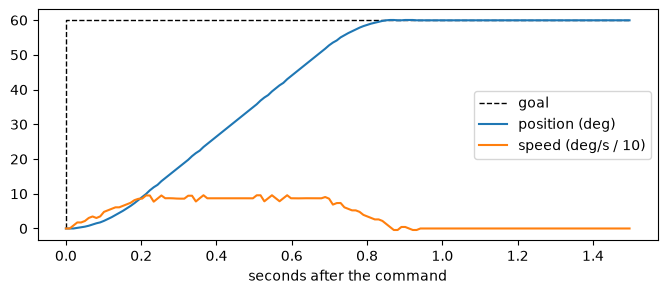

In [4]:
# the config says "sim", so this returns the twin; check it is the same class as the real arm
from common.motion import LeRobotArm, make_arm_backend

arm = make_arm_backend(cfg)
print(f"{type(arm).__name__} is a LeRobotArm: {isinstance(arm, LeRobotArm)}")
print("at rest:", {k: round(v, 1) for k, v in arm.get_joints().items()})


# give one joint a single goal, then read its angle 100 times a second
def step_response(joint, delta, seconds=1.5, hz=100):
    """Send one goal, then sample the joint - what a scope on the servo would show."""
    q0 = arm.get_joints()[joint]
    arm.send_joints({joint: q0 + delta})
    t, q, t0 = [], [], time.perf_counter()
    while (now := time.perf_counter() - t0) < seconds:
        t.append(now)
        q.append(arm.get_joints()[joint])
        time.sleep(1.0 / hz)
    return np.array(t), np.array(q) - q0


# turn the base 60 degrees; from the samples, get the top speed and the time to 95% of the turn
t, q = step_response("shoulder_pan", 60.0)
v = np.gradient(q, t)
t95 = t[np.argmax(q >= 0.95 * 60.0)]
print(f"peak speed {v.max():.0f} deg/s, 95% of the step after {t95:.2f} s")

# plot the goal (dashed), the angle, and the speed scaled down to fit
fig, ax = plt.subplots(figsize=(8, 3))
ax.step([0, 0, t[-1]], [0, 60, 60], "k--", lw=1, where="post", label="goal")
ax.plot(t, q, label="position (deg)")
ax.plot(t, v / 10, label="speed (deg/s / 10)")
ax.set_xlabel("seconds after the command")
ax.legend()
plt.show()
# back to the rest pose
arm.go_to_rest()

## 2. It sees like the arm

A camera is a pinhole at a pose. The twin's `wrist_cam` sits where the real
arm camera is mounted - beside the gripper, looking along the jaws - so it
moves with the wrist and sees what is being gripped. A render thread draws
every camera on the iGPU (EGL), separate from the physics thread, and
`SimCamera.read()` returns `(ok, bgr)` exactly like `cv2.VideoCapture`.

Present the open jaws, put the toothbrush between them, and look from both
the wrist and a free 3D view.

renderer: AMD Radeon Graphics (radeonsi, gfx1151, LLVM 20.1.2, DRM 3.64, 7.0.0-38-generic)


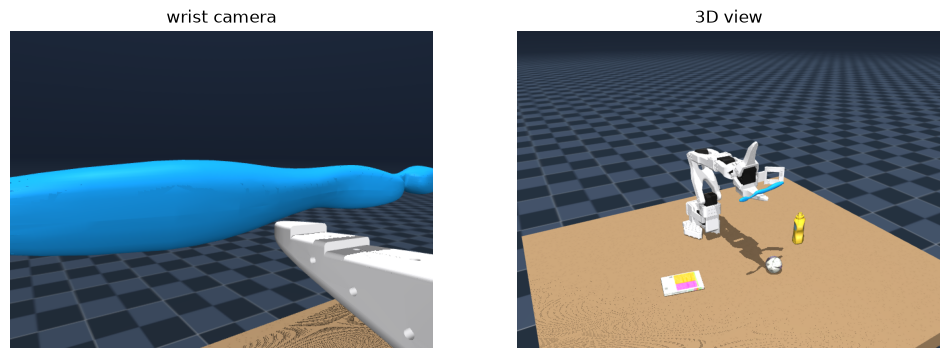

In [5]:
# simulated cameras, and the renderer that draws their images
from so101_sim import SimCamera
from so101_sim.render import shared_renderer

# joint angles (degrees) for a pose that presents the open jaws
PRESENT = {"shoulder_pan": 0.0, "shoulder_lift": -35.0, "elbow_flex": 30.0, "wrist_flex": 10.0, "wrist_roll": 0.0}

# two cameras, each read like a webcam: read() returns (ok, image)
wrist = SimCamera(world, "arm")  # the arm camera, on the wrist
view = SimCamera(world, "view", width=800, height=600)  # a free 3D view, for us

# move there with the jaws open, put the toothbrush between them, and take one picture from each camera
arm.go_to({**PRESENT, "gripper": 85.0})
time.sleep(1.0)  # let the jaws finish opening
world.stage_object("toothbrush", PRESENT)
_, w_img = wrist.read(fresh=True)
_, v_img = view.read(fresh=True)
print("renderer:", shared_renderer(world).renderer)

# show both pictures side by side (OpenCV images are BGR, matplotlib wants RGB)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, img, title in zip(axes, (w_img, v_img), ("wrist camera", "3D view")):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.show()
world.place("toothbrush", world.model.body("toothbrush").pos)  # back on the table

## 3. It feels like the arm

The real gripper has no touch sensor. The grip behavior infers contact from
the servo's `Present_Current`: closing on nothing, the motor reaches its
goal and the current falls away; closing on an object, the jaws stall and
the motor pushes against it, so the current stays high.

The twin produces that current from the physics - the actuator effort the
contact actually demands - not from a script. Close the jaws twice, once
empty and once on the ball, and compare against the threshold.

peak current - empty jaws: 108   ball: 201   (threshold 120)


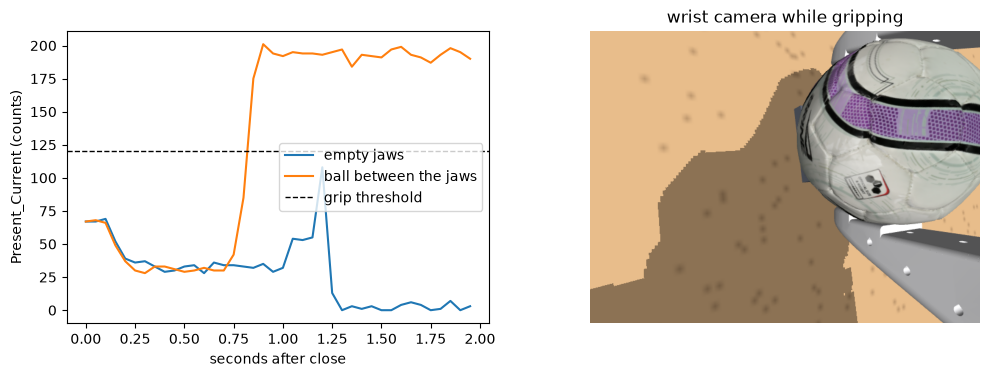

In [6]:
# the gripper angle sent as the "fully closed" goal
from common.motion import GRIPPER_CLOSED_FLOOR

# jaws at table height, closing sideways - how pick_place grasps the ball
GRASP = {"shoulder_pan": 0.0, "shoulder_lift": 9.0, "elbow_flex": 20.0, "wrist_flex": 54.0, "wrist_roll": 0.0}


# close the jaws at GRASP, with or without the ball between them, and record the gripper current
def squeeze(with_object, seconds=2.0, hz=20):
    """Open at GRASP, optionally place the ball, then return the current trace."""
    arm.go_to({**GRASP, "gripper": 85.0})
    time.sleep(1.0)
    if with_object:
        world.stage_object("sports_ball", GRASP)
    else:
        world.hide("sports_ball")
    arm.send_joints({"gripper": GRIPPER_CLOSED_FLOOR})
    trace = []
    for _ in range(int(seconds * hz)):
        time.sleep(1.0 / hz)
        trace.append(arm.get_gripper_load() or 0.0)
    _, img = wrist.read(fresh=True)
    arm.go_to({"gripper": 85.0})  # let go
    return np.array(trace), img


# close once on nothing and once on the ball; only the ball should keep the current above the threshold
empty, _ = squeeze(with_object=False)
held, held_view = squeeze(with_object=True)
print(f"peak current - empty jaws: {empty.max():.0f}   ball: {held.max():.0f}   (threshold {LOAD_THRESHOLD:.0f})")

# both current traces against the threshold, beside the wrist camera's view of the grip
fig, (ax, ax_img) = plt.subplots(1, 2, figsize=(12, 3.8))
t = np.arange(len(held)) / 20
ax.plot(t, empty, label="empty jaws")
ax.plot(t, held, label="ball between the jaws")
ax.axhline(LOAD_THRESHOLD, color="k", ls="--", lw=1, label="grip threshold")
ax.set_xlabel("seconds after close")
ax.set_ylabel("Present_Current (counts)")
ax.legend()
ax_img.imshow(cv2.cvtColor(held_view, cv2.COLOR_BGR2RGB))
ax_img.set_title("wrist camera while gripping")
ax_img.axis("off")
plt.show()
# world.model is the scene file, so this is the ball's home position in scene_vvla.xml
world.place("sports_ball", world.model.body("sports_ball").pos)
arm.go_to_rest()

## 4. Find it, reach it, grab it

To pick up an object, the arm does three things:

1. **Find it:** YOLO draws a box around it in the wrist camera image.
2. **Locate it:** the box is turned into a position on the table, in metres.
3. **Reach it:** inverse kinematics finds the joint angles that put the open jaws around it.

The next cell turns the command into an object name and turns the arm until YOLO finds it.

'pick up the ball' -> {'command': 'pick_place', 'object': 'ball'} -> COCO class 'sports ball'
YOLO detect on VitisAIExecutionProvider
pan    +0 deg: no match
pan   -14 deg: sports ball, score 0.51


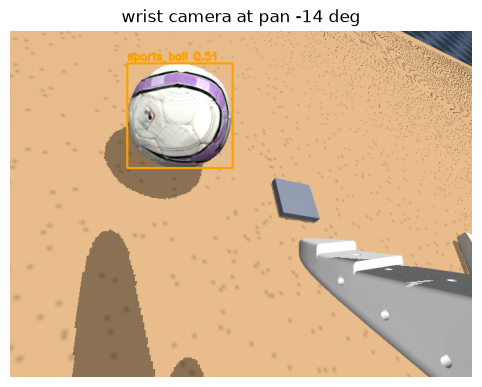

In [7]:
# the object detector, and helpers that turn a command into a COCO class name
from common.fixtures import offline_parse_text
from common.imaging import resolve_class
from models.vision import ObjectDetector

# the command to act on; try another object here
COMMAND = "pick up the ball"

# load YOLO, and get the object name out of the command
detector = ObjectDetector(cfg)  # YOLOv26s detect; the console below reuses it
intent = offline_parse_text(COMMAND)  # the keyword stand-in for Llama
name = intent["object"]
print(f"{COMMAND!r} -> {intent} -> COCO class {resolve_class(name)!r}")
print(f"YOLO detect on {detector.provider}")

# turn the base through the scan angles, take a wrist-camera frame at each, and stop at the first that shows the object
pp = cfg["pick_place"]
for pan in pp["scan_pans"]:
    arm.go_to({**pp["scan_pose"], "shoulder_pan": pan})
    time.sleep(0.3)  # let the pan settle before the frame is taken
    scan_joints = arm.get_joints()
    _, frame = wrist.read(fresh=True)
    dets, cls = detector.find(frame, name)
    print(f"pan {pan:+5.0f} deg: " + (f"{cls}, score {dets[0].score:.2f}" if dets else "no match"))
    if dets:
        break
# stop here if no view showed it; otherwise keep the first detection
assert dets, f"no {name} in any scan view"
det = dets[0]

# show the frame with the detection box drawn on it
plt.figure(figsize=(6, 4.5))
plt.imshow(cv2.cvtColor(detector.draw(frame, [det]), cv2.COLOR_BGR2RGB))
plt.title(f"wrist camera at pan {pan:+.0f} deg")
plt.axis("off")
plt.show()

### Finding the requested object

The arm knows its joint angles, so it knows where the camera is and which way it points. Each pixel in the image is a direction from the camera. The object sits on the table, so the line through the bottom of the box hits the table where the object is. That gives its position from one image.

The twin knows the true position, so the plot shows how close the estimate is.

sphere fit: centre (0.280, 0.060, 0.015) m, 40 mm wide
ground truth: centre (0.280, 0.060, 0.015) m
error: 0.4 mm on the table, 0.0 mm in height


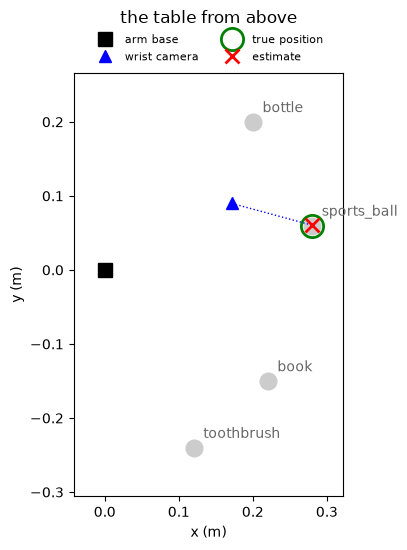

In [8]:
# the arm's kinematics, and which object classes are round or flat
from so101_sim.kinematics import FLAT_CLASSES, ROUND_CLASSES, shared_kinematics

# the camera's lens model (K, dist) for this image size, and the table height
kin = shared_kinematics(GRIPPER_CLOSED_FLOOR)  # MuJoCo's model of the arm, for FK and IK
arm_cam = cfg["cameras"]["arm"]
h, w = frame.shape[:2]
K, dist = kin.intrinsics(arm_cam.get("intrinsics"), w, h)
table_z = float(pp["table_z"])
# the shape the fit assumes: a ball, a flat object, the bottle, or another standing object
shape = ("sphere" if cls in ROUND_CLASSES else "flat" if cls in FLAT_CLASSES
         else "bottle" if cls == "bottle" else "upright")
# turn the pixel box into a position on the table, in metres from the arm's base
loc = kin.locate_on_table(det.box, scan_joints, K, dist, arm_cam.get("mount"), table_z, (w, h), shape=shape)
assert loc is not None, "the box touches the image edge - no table fix"

# where the twin really put the object, and where the camera was
body = cls.replace(" ", "_")  # the twin's body for this class
truth = world.body_pos(body)
camera_xyz = kin.camera_pose(scan_joints, arm_cam.get("mount"))[1]
# print the estimate, the true position, and the difference
xyz = lambda v: "(" + ", ".join(f"{c:.3f}" for c in v) + ") m"
print(f"{shape} fit: centre {xyz(loc['xyz'])}, {1000 * loc['width']:.0f} mm wide")
print(f"ground truth: centre {xyz(truth)}")
print(f"error: {1000 * np.linalg.norm(loc['xyz'][:2] - truth[:2]):.1f} mm on the table, "
      f"{1000 * abs(loc['xyz'][2] - truth[2]):.1f} mm in height")

# top view of the table: every object, the arm base, the camera, the estimate and the truth
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for other in world.objects:
    o = world.body_pos(other)[:2]
    ax.plot(*o, "o", color="0.8", ms=12)
    ax.annotate(other, o, xytext=(7, 7), textcoords="offset points", color="0.4")
ax.plot(0, 0, "ks", ms=10, label="arm base")
ax.plot(*camera_xyz[:2], "b^", ms=9, label="wrist camera")
ax.plot([camera_xyz[0], loc["xyz"][0]], [camera_xyz[1], loc["xyz"][1]], "b:", lw=1)
ax.plot(*truth[:2], "o", mfc="none", mec="g", ms=16, mew=2, label="true position")
ax.plot(*loc["xyz"][:2], "rx", ms=10, mew=2, label="estimate")
ax.set_aspect("equal")
ax.margins(0.15)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("the table from above", pad=36)
# above the axes, so it cannot cover an object
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8, frameon=False)
plt.show()

### Reaching the object

`solve_grasp` finds two arm poses:

- the **grasp**, with the open jaws around the object;
- the **pre-grasp**, the same jaws a few centimetres straight above it.

The arm moves to the pre-grasp, goes straight down to the grasp, and only then closes the jaws. Coming down from above keeps the jaws from knocking the object over.

In [9]:
# joint limits: the usual ones, and the wider wrist range for standing objects
from common.motion import GRASP_LIMITS, JOINT_LIMITS

# the point to grasp, the limits to use, and an obstacle for a standing object
p = loc["xyz"].copy()
p[2] = min(p[2], table_z + pp["max_grasp_height_m"])  # a tall object is held low
standing = shape in ("bottle", "upright")
# a standing object's own volume, an upright cylinder (x, y, radius, top)
obstacle = (*loc["xyz"][:2], loc["width"] / 2, table_z + loc["height"]) if standing else None
limits = GRASP_LIMITS if standing else JOINT_LIMITS

# solve for the grasp pose and the pre-grasp above it, and time the solve
t0 = time.perf_counter()
plan = kin.solve_grasp(p, above_m=pp["pregrasp_above_m"], width=loc["width"], table_z=table_z,
                       limits=limits, obstacle=obstacle)
print(f"solve_grasp: {1000 * (time.perf_counter() - t0):.0f} ms")
assert plan is not None, f"no grasp of the {cls} within the arm's joint limits"
# print both poses as joint angles
pre, grasp = plan
for label, q in (("pre-grasp", pre), ("grasp", grasp)):
    print(f"{label:>9}: " + "  ".join(f"{k} {v:+6.1f}" for k, v in q.items()))

# check the answer: how close the jaws are to the centre, how level they are,
# how high the arm stays above the table, and whether every joint is in range
off = kin.world.grasp_point(grasp, loc["width"]) - p
tilt = np.degrees(np.arcsin(min(abs(kin.world.jaw_axis(grasp)[2]), 1.0)))
inside = all(lo <= grasp[k] <= hi and lo <= pre[k] <= hi for k, (lo, hi) in limits.items() if k in grasp)
print(f"grasp point: {1000 * np.linalg.norm(off[:2]):.1f} mm from the centre, {1000 * off[2]:+.1f} mm in height")
print(f"closing axis: {tilt:.1f} deg from horizontal")
print(f"lowest arm part at the grasp: {1000 * (kin.lowest_point(grasp) - table_z):.0f} mm above the table")
print(f"joints inside the grasp limits: {inside}")
if obstacle:
    print(f"hand above the {cls} at the pre-grasp: {1000 * kin.hand_clearance(pre, obstacle):.0f} mm")

solve_grasp: 50 ms
pre-grasp: shoulder_pan  -14.4  shoulder_lift   -3.6  elbow_flex  +12.8  wrist_flex  +67.5  wrist_roll   +0.0  gripper  +75.0
    grasp: shoulder_pan  -14.4  shoulder_lift  +18.3  elbow_flex   +4.3  wrist_flex  +67.5  wrist_roll   +0.0  gripper  +75.0
grasp point: 0.1 mm from the centre, +6.0 mm in height
closing axis: 0.0 deg from horizontal
lowest arm part at the grasp: 5 mm above the table
joints inside the grasp limits: True


### Grabbing the object

The next cell runs that plan on the twin: move above the object, go down, close the jaws until they touch it (as in section 3), and lift. The plot shows the object's height. If it rises with the arm, the grasp worked.

contact: True, jaws holding at 47 deg
sports ball lifted 45 mm; held between both jaws: True; holding() after the lift: True
moved 0.1 mm in the gripper after lift-off (held still: well under 2 mm)


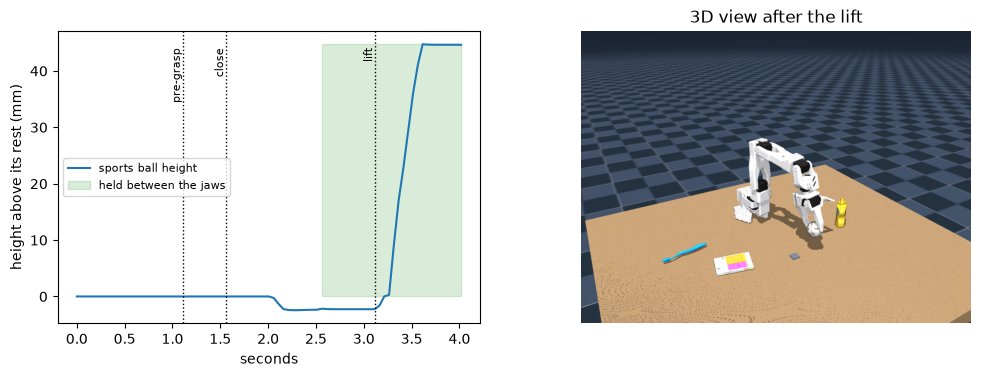

In [10]:
# joint steps between two poses, the contact close, and the open-jaw park
from so101_sim.kinematics import joint_line
from common.manipulation import close_with_feedback, holding, park_open

# descent from the pre-grasp, the object's rest height, and the trace the recorder fills
g = cfg["grip"]
down = joint_line(pre, grasp)
z0 = world.body_pos(body)[2]
trace, marks = [], {}
recording = threading.Event()
recording.set()
t0 = time.perf_counter()


# height, both-jaw contact, and the point in the gripper frame, twenty times a second
def record(hz=20):
    while recording.is_set():
        trace.append((time.perf_counter() - t0, world.body_pos(body)[2] - z0, world.is_grasped(body),
                      world.in_gripper(body)))
        time.sleep(1.0 / hz)


# keep recording through the move
threading.Thread(target=record, daemon=True).start()
# open jaws, in joint steps, from the scan pose to the pre-grasp
transfer = joint_line(arm.get_joints(), pre)
for q in transfer:
    arm.go_to(q, duration_s=1.5 / len(transfer), limits=limits)
marks["pre-grasp"] = time.perf_counter() - t0
# straight down onto the grasp; the jaws stay as they are
for q in down:
    arm.go_to(q, duration_s=1.5 / len(down), limits=limits)
marks["close"] = time.perf_counter() - t0
# close until the jaws stop on the object; the goal stays past that angle
gripped, hold = close_with_feedback(arm, g, start_from=75.0)
marks["lift"] = time.perf_counter() - t0
# back up the same joints, holding the measured angle so the jaws do not open
for q in [*reversed(down[:-1]), pre]:
    arm.go_to({**q, "gripper": hold}, duration_s=1.5 / len(down), limits=limits)
# one more half-second of the hold, then the frame the plot shows
time.sleep(0.5)
recording.clear()
_, lifted = view.read(fresh=True)

# how high it rose, and how far it drifted in the hand after leaving the table
t, dz, held, in_hand = (np.array(v) for v in zip(*trace))
off = int(np.argmax(dz > 0.005))  # first sample off the table
slip = np.linalg.norm(in_hand[off:] - in_hand[off], axis=1).max()
print(f"contact: {gripped}, jaws holding at {hold:.0f} deg")
print(f"{cls} lifted {1000 * dz[-1]:.0f} mm; held between both jaws: {bool(held[-1])}; "
      f"holding() after the lift: {holding(arm, g, hold)}")
print(f"moved {1000 * slip:.1f} mm in the gripper after lift-off (held still: well under 2 mm)")

# height over time, with the three marks, beside the twin after the lift
fig, (ax, ax_img) = plt.subplots(1, 2, figsize=(12, 3.8))
ax.plot(t, 1000 * dz, label=f"{cls} height")
ax.fill_between(t, 0, 1000 * dz.max(), where=held, color="g", alpha=0.15, label="held between the jaws")
for label, at in marks.items():
    ax.axvline(at, color="k", ls=":", lw=1)
    ax.text(at, 1000 * dz.max(), f"{label} ", rotation=90, ha="right", va="top", fontsize=8)
ax.set_xlabel("seconds")
ax.set_ylabel("height above its rest (mm)")
ax.legend(loc="center left", fontsize=8)
ax_img.imshow(cv2.cvtColor(lifted, cv2.COLOR_BGR2RGB))
ax_img.set_title("3D view after the lift")
ax_img.axis("off")
plt.show()

arm.go_to({"gripper": JOINT_LIMITS["gripper"][1]})  # let go
park_open(arm)  # home with the jaws open, so they cannot catch it again
# world.model is the scene file: its home position in scene_vvla.xml, but not its
# home rotation (place() sets none), so a toothbrush or book comes back turned straight
world.place(body, world.model.body(body).pos)

### What the full behavior adds

When you say "pick up ..." in the console below, the arm does the same steps. If the grasp slips, it tries once more. If the object falls, it tells you.

## 5. Control the digital twin

Now you control the twin by voice or by typing, with the workshop's behaviors:

1. **Run the twin as its own program.** It leaves this notebook and runs as a separate ROS 2 program, like the real arm's software. The notebook talks to it only through ROS 2 messages, as it would to the real arm.
2. **Watch you** through your webcam.
3. **Listen to you:** Whisper turns speech into text, Llama picks a command.
4. **Take commands** in the live console.

The twin uses a private ROS 2 network (domain 87) that only this computer sees, so the real arm never receives its commands.

In [11]:
# start the twin as its own ROS 2 program, on a private ROS 2 network
from common.ros_helpers import ros2_available
from so101_sim import close_shared_world

assert ros2_available(), (
    "section 5 runs the twin as a ROS 2 node and needs rclpy: source /opt/ros/jazzy/setup.bash, "
    "then restart ./run_notebooks.sh"
)
from common.twin_ros import TwinSession

# the objects where sections 2-4 left them; the new twin starts with the arm at rest
scene = world.snapshot_scene()
# close this kernel's twin, so only one twin runs from here on
wrist.release()
view.release()
arm.close()
close_shared_world()
# start the twin program and connect the arm, the wrist camera, the 3D view and the scene to it
twin = TwinSession(cfg, scene=scene)
arm, wrist, view = twin.arm, twin.armcam, twin.view
print(f"twin node pid {twin.pid} on ROS domain {twin.domain_id} (this machine only)")
print(f"arm: {type(arm).__name__} -> {cfg['robot']['command_topic']}")

twin node pid 255180 on ROS domain 87 (this machine only)
arm: TwinArmClient -> /so101/joint_command


### Watching you

The next cell loads the pose and hand models, builds the console, and shows ten seconds of your webcam the way the two models see it. The tile titles show which processor runs each model. Without a webcam, a scripted person stands in.

In [12]:
# your webcam, YOLO-pose and MediaPipe Hands, and the console that shows what they find
from common.twin_console import TwinConsole, jpeg, open_webcam

cam, pose, hands = open_webcam(cfg)  # a scripted person if the webcam gives no frames
console = TwinConsole(arm, operator=cam, pose=pose, hands=hands, armcam=wrist, detector=detector,
                      view=view, load_threshold=LOAD_THRESHOLD)

# ten seconds of your webcam, as the two models see it
preview = widgets.Image(format="jpeg")
display(preview)
for _ in range(10 * 15):
    preview.value = jpeg(console.webcam_tiles())
    time.sleep(1 / 15)

Image(value=b'', format='jpeg')

### Listening to you

Your voice reaches the robot in four steps:

1. **The VAD** (voice activity detection, CPU) listens to the microphone all the time and finds where a sentence starts and ends. A sentence ends after 1.2 s of silence, so the text appears about a second after you stop talking. Sounds shorter than 0.25 s, such as a click, are dropped.
2. **Whisper** (CPU) turns that sentence into text.
3. **Llama** (iGPU) reads the text, works out what you want, and answers with one robot command, for example `pick_place` with the object `ball`.
4. The **behavior** for that command runs on the arm. A new command stops the one that is running.

Two kinds of text never reach Llama. "stop" stops the arm at once, so a stop never waits for the language model. Noise, such as a cough or keyboard clicks, is ignored. `handle_transcript` (TODO 3.2) makes these checks.

The VAD is WebRTC's voice activity detector, a small statistical model rather than a neural network; [Voice latency](../../../README.md#voice-latency) in the top-level README explains how it works. Here it runs in `Segmenter` in `common/speech.py`, with its settings under `audio:` in `config/workshop.yaml`.

The next cell starts the microphone and asks you for one command. It prints the text Whisper heard and the command Llama made of it, but runs nothing yet. Without a microphone it uses a typed sentence; without llama-server, a keyword match stands in for Llama.

In [13]:
# what every behavior gets: the config, the arm, the cameras and the models
from common.motion import mapper_from_config
from common.twin_voice import VoiceCommands
from integration.dispatch import WorkshopContext

ctx = WorkshopContext(
    cfg=cfg,
    arm=arm,
    camera=console.operator,  # behaviors and the console share the same webcam frames
    pose=pose,
    hands=hands,
    detector=detector,  # pick_place finds objects with it
    arm_camera=console.armcam,  # the twin's wrist camera, for grip and pick_place
    mapper=mapper_from_config(cfg),
    headless=True,  # behaviors draw into the console, never their own window
)
ctx.say = console.say  # robot speech lands in the voice panel
# the microphone, Whisper, Llama, and the queue that runs one command at a time
voice = VoiceCommands(cfg, ctx, console, twin)

# say one command: what Whisper heard, and the command Llama picks (nothing runs yet)
voice.listen()

Say a command, for example "pick up the ball". Listening for 20 s...
Nothing heard in 20 s. Is the microphone muted?


### Controlling the digital twin

Run the next cell, then speak or type. Under the console, **stop** ends the cell and parks the arm, **reset** parks the arm and puts the objects back, and **end session** also ends the cell (run the cell again to resume). Saying "stop" only halts the behavior, so a later command in the same session still works. The notebook runs one cell at a time, so click **stop** or **end session** (or the kernel's stop button) before you run the clean-up cell.

| Say | What happens |
|---|---|
| "copy my movements" | The arm follows your right hand: where it is in the image, how close it is to the camera, its tilt, and your pinch for the gripper. |
| "pick up the ball" (or bottle, book, toothbrush) | The wrist camera finds the object; the arm grasps it, lifts it and holds it out. |
| "hold this" | The jaws close on what is between them and keep holding. If you then say "copy my movements", your pinch controls the gripper. |
| "release", "drop it" | The jaws open. |
| "wave", "dance" | The arm waves, or dances to a beat. |
| "go home" | The arm returns to its rest pose. |
| "stop" | Everything stops at once. |

All commands: [Voice commands → behaviors](../../../README.md#voice-commands--behaviors).

In [14]:
# the console image with its buttons and text box, redrawn FPS times a second
FPS = 15
# Start with a frame, not empty: JupyterLab may not re-measure an image that grows later.
screen = widgets.Image(value=jpeg(console.compose()), format="jpeg", layout=widgets.Layout(width="1200px"))
stop = widgets.Button(description="stop", button_style="danger")
reset = widgets.Button(description="reset", button_style="warning")
typed = widgets.Text(placeholder="or type a command, then Enter", continuous_update=False,
                     layout=widgets.Layout(width="400px"))
end = widgets.Button(description="end session")
finished = threading.Event()  # set by stop or end session


def submit(change):
    """Enter in the text box sends the typed command, the same way as a spoken one."""
    text = change["new"].strip()
    if text:
        typed.value = ""
        voice.on_transcript(text)


def end_session(_=None):
    """Ends the loop below and the running behavior."""
    finished.set()
    ctx.stop_event.set()


stop.on_click(end_session)  # the red button ends the cell; saying "stop" only halts the behavior
reset.on_click(voice.reset_scene)
typed.observe(submit, names="value")
end.on_click(end_session)
display(widgets.VBox([screen, widgets.HBox([stop, reset, typed, end])]))

# run commands on their own thread, one at a time, and redraw the console until stop or end session
console.say("Ready. Try: 'copy my movements', 'hold this', 'pick up the ball', 'pick up the bottle', "
            "'pick up the book', 'pick up the toothbrush', 'wave', 'dance', 'go home' - or 'stop'.")
dispatcher = threading.Thread(target=voice.dispatch_loop, args=(finished,), daemon=True)
dispatcher.start()
try:
    # running this cell again while it runs (JupyterLab's run and advance) also ends the session
    with ui_events(on_rerun=end_session) as poll:
        while not finished.is_set():
            t0 = time.perf_counter()
            poll(10)  # deliver button clicks and typed commands while this cell runs
            screen.value = jpeg(console.compose())
            time.sleep(max(0.0, 1.0 / FPS - (time.perf_counter() - t0)))
finally:
    # stop, end session, or the kernel's stop button: stop the dispatcher, wait for the last behavior, park the arm
    finished.set()
    ctx.stop_event.set()
    dispatcher.join(timeout=10)
    arm.go_to_rest()
    print("session ended, arm parked")

Ready. Try: 'copy my movements', 'hold this', 'pick up the ball', 'pick up the bottle', 'pick up the book', 'pick up the toothbrush', 'wave', 'dance', 'go home' - or 'stop'.
Looking for a toothbrush.
Got the toothbrush.
Done.
Released.
Looking for a bottle.
Got the bottle.
Done.
Your pinch drives the gripper now. Open your fingers to let go.
Looking for a toothbrush.
Got the toothbrush.
Done.
Released.
session ended, arm parked


### Running it outside the notebook

This section ran the finished TODO code in `workshop/solution/`. Your version is in `workshop/project/`, in the same files:

- `models/`: `npu.py` (TODOs 1.1-1.3), `hands.py` (1.4), `llm.py` (1.5-1.6)
- `ros/`: `arm_node.py` (2.4-2.6), `arm_client.py` (2.7-2.9)
- `integration/`: `dispatch.py` (3.1-3.2), `mimic.py` (3.3), `behaviors.py` (3.4)

To drive the twin with your version, run `python app.py --digital-twin` in `workshop/project/`.

## Clean up

Click **stop** or **end session** under the console (or the kernel's stop button) before you run this cell. It closes the microphone, the cameras, the twin program and, if this notebook started it, Llama.

In [15]:
# the console cell ended its session; this also ends a dispatcher it left running
finished.set()
ctx.stop_event.set()
dispatcher.join(timeout=5)
# close everything that holds a device or a process
voice.close()  # the microphone, and llama-server if this notebook started it
console.close()  # stops sharing the camera frames and closes both cameras
hands.close()
twin.close()  # the arm client, the 3D view, the scene, and the twin program
print("twin closed")

twin closed
